# Projet de Machine Learning 

### Sujet 1

**Contexte** :  Ce projet vise à mettre en place un système de maintenance prédictive pour les machines de l'usine et à analyser les causes qui font que la condition de la valve d'un cycle de production est non optimale parfois. 

**Objectif** : Construisez un modèle ML pour prédire si la condition valve est optimale (=100%) ou non, pour chaque cycle. Vous utiliserez les 2000 premiers cycles pour construire le modèle et le reste comme échantillon de test final.   

**Données** : Les données sont disponibles dans un Drive. Les données sont décrites à utiliser uniquement les 3 fichiers suivants, chaque ligne représentant un cycle :  
- PS2 (Pression (bar) échantillonnage 100Hz)  
- FS1 (Volume flow (l/min) échantillonnage 10Hz)  
- Profile : Fichier avec les variables dont la "valve condition" qui nous intéresse. 

## 1. Prétraitement des données

#### 1.1. Chargement des données et statistiques descriptives. 

In [1]:
# 1.1 Chargement des données et statistiques descriptives
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'     # dossier contenant PS2.txt, FS1.txt et profile.txt
N_DEV = 2000          # 2000 premiers cycles : construction du modèle
RANDOM_STATE = 42

# Une ligne = un cycle. Fichiers sans en-tête, colonnes séparées par des tabulations.
ps2 = pd.read_csv(f'{DATA_DIR}/PS2.txt', sep=r'\s+', header=None)
fs1 = pd.read_csv(f'{DATA_DIR}/FS1.txt', sep=r'\s+', header=None)
profile = pd.read_csv(f'{DATA_DIR}/profile.txt', sep=r'\s+', header=None, names=['Cooler', 'Valve', 'Pump_leakage', 'Accumulator', 'Stable_flag'])

print('PS2     :', ps2.shape, '(cycles x mesures à 100 Hz)')
print('FS1     :', fs1.shape, '(cycles x mesures à 10 Hz)')
print('profile :', profile.shape)
assert len(ps2) == len(fs1) == len(profile), 'Nombre de cycles incohérent entre les fichiers'
profile.head()

PS2     : (2205, 6000) (cycles x mesures à 100 Hz)
FS1     : (2205, 600) (cycles x mesures à 10 Hz)
profile : (2205, 5)


,Cooler,Valve,Pump_leakage,Accumulator,Stable_flag
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


In [2]:
# 1.1 (suite) Séparation : 2000 premiers cycles (développement) / cycles restants (test final)
# Le test final ne sera PAS utilisé avant l'évaluation finale.
ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
profile_dev, profile_test = profile.iloc[:N_DEV], profile.iloc[N_DEV:]

print('Cycles de développement :', len(profile_dev))
print('Cycles de test final    :', len(profile_test))

Cycles de développement : 2000
Cycles de test final    : 205


In [3]:
# 1.1 (suite) Statistiques descriptives (sur les 2000 cycles de développement)
print('--- profile.txt (conditions des composants) ---')
print(profile_dev.describe().round(2))

print('\n--- Signaux bruts (toutes les mesures des cycles de développement) ---')
for nom, df in [('PS2 (bar)', ps2_dev), ('FS1 (l/min)', fs1_dev)]:
    v = df.to_numpy().ravel()
    print(f'{nom:12s} min={v.min():8.2f} | moyenne={v.mean():8.2f} | médiane={np.median(v):8.2f} | '
          f'max={v.max():8.2f} | écart-type={v.std():7.2f}')

--- profile.txt (conditions des composants) ---
        Cooler    Valve  Pump_leakage  Accumulator  Stable_flag
count  2000.00  2000.00       2000.00      2000.00      2000.00
mean     35.22    90.95          0.67       108.65         0.37
std      39.88    10.67          0.82        16.53         0.48
min       3.00    73.00          0.00        90.00         0.00
25%       3.00    80.00          0.00        90.00         0.00
50%      20.00   100.00          0.00       100.00         0.00
75%     100.00   100.00          1.00       130.00         1.00
max     100.00   100.00          2.00       130.00         1.00

--- Signaux bruts (toutes les mesures des cycles de développement) ---
PS2 (bar)    min=    0.00 | moyenne=  109.39 | médiane=  125.66 | max=  167.74 | écart-type=  48.18
FS1 (l/min)  min=    0.00 | moyenne=    6.16 | médiane=    7.64 | max=   20.48 | écart-type=   3.23


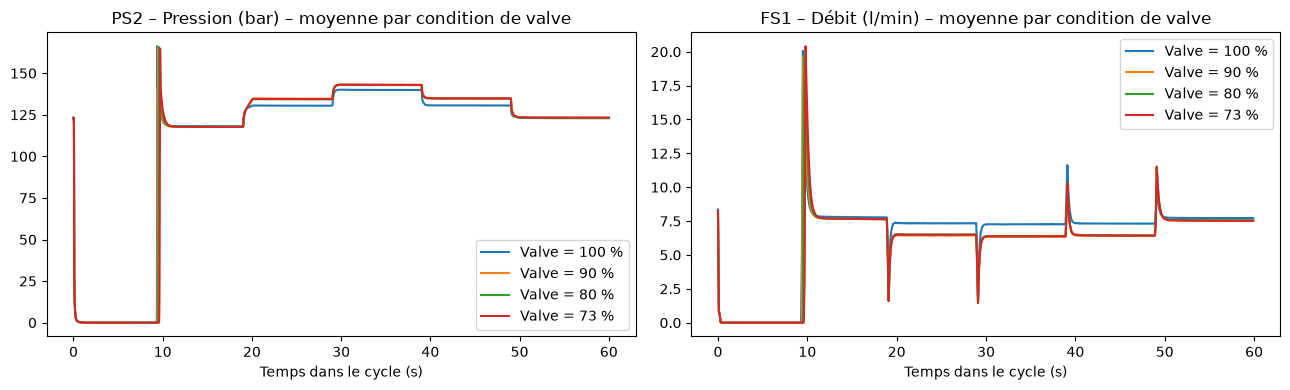

In [4]:
# 1.1 (suite) Allure moyenne d'un cycle selon la condition de la valve
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom, df, hz) in zip(axes, [('PS2 – Pression (bar)', ps2_dev, 100), ('FS1 – Débit (l/min)', fs1_dev, 10)]):
    t = np.arange(df.shape[1]) / hz
    for val in sorted(profile_dev['Valve'].unique(), reverse=True):
        masque = (profile_dev['Valve'] == val).to_numpy()
        ax.plot(t, df[masque].mean(axis=0), label=f'Valve = {val} %')
    ax.set_title(nom + ' – moyenne par condition de valve')
    ax.set_xlabel('Temps dans le cycle (s)')
    ax.legend()
plt.tight_layout()
plt.show()

#### 1.2. Gestion des valeurs manquantes et détection des valeurs aberrantes.

In [5]:
# 1.2 Valeurs manquantes : comptage (contrôle d'intégrité sur l'ensemble des fichiers)
n_ps2, n_fs1, n_prof = int(ps2.isnull().sum().sum()), int(fs1.isnull().sum().sum()), int(profile.isnull().sum().sum())
print('Valeurs manquantes PS2     :', n_ps2)
print('Valeurs manquantes FS1     :', n_fs1)
print('Valeurs manquantes profile :', n_prof)

Valeurs manquantes PS2     : 0
Valeurs manquantes FS1     : 0
Valeurs manquantes profile : 0


In [6]:
# Gestion : interpolation le long du cycle (ligne par ligne, donc sans fuite entre cycles) uniquement si nécessaire
if n_ps2 or n_fs1:
    ps2 = ps2.interpolate(axis=1, limit_direction='both')
    fs1 = fs1.interpolate(axis=1, limit_direction='both')
    ps2_dev, ps2_test = ps2.iloc[:N_DEV], ps2.iloc[N_DEV:]
    fs1_dev, fs1_test = fs1.iloc[:N_DEV], fs1.iloc[N_DEV:]
    print('-> Valeurs manquantes interpolées le long de chaque cycle.')
else:
    print('-> Aucune valeur manquante dans les signaux : aucune imputation nécessaire.')
assert n_prof == 0, 'profile.txt contient des valeurs manquantes : à traiter avant de continuer'

-> Aucune valeur manquante dans les signaux : aucune imputation nécessaire.


In [7]:
# 1.2 (suite) Résumé de chaque cycle par des statistiques (tableau de variables)
def extraire_features(df, prefixe, n_segments=6):
    X = df.to_numpy(dtype=float)
    f = pd.DataFrame(index=df.index)
    f[f'{prefixe}_mean'] = X.mean(axis=1)
    f[f'{prefixe}_std'] = X.std(axis=1)
    f[f'{prefixe}_min'] = X.min(axis=1)
    f[f'{prefixe}_max'] = X.max(axis=1)
    f[f'{prefixe}_median'] = np.median(X, axis=1)
    f[f'{prefixe}_range'] = f[f'{prefixe}_max'] - f[f'{prefixe}_min']
    f[f'{prefixe}_q25'] = np.percentile(X, 25, axis=1)
    f[f'{prefixe}_q75'] = np.percentile(X, 75, axis=1)
    f[f'{prefixe}_iqr'] = f[f'{prefixe}_q75'] - f[f'{prefixe}_q25']
    f[f'{prefixe}_skew'] = stats.skew(X, axis=1)
    f[f'{prefixe}_kurtosis'] = stats.kurtosis(X, axis=1)
    f[f'{prefixe}_rms'] = np.sqrt((X ** 2).mean(axis=1))
    t = np.arange(X.shape[1]) - (X.shape[1] - 1) / 2          # pente de la tendance linéaire
    f[f'{prefixe}_slope'] = (X - X.mean(axis=1, keepdims=True)) @ t / (t ** 2).sum()
    for i, seg in enumerate(np.array_split(X, n_segments, axis=1)):   # moyenne par tranche de temps
        f[f'{prefixe}_seg{i + 1}_mean'] = seg.mean(axis=1)
    return f

features = pd.concat([extraire_features(ps2, 'PS2'), extraire_features(fs1, 'FS1')], axis=1)
X_dev, X_test = features.iloc[:N_DEV], features.iloc[N_DEV:]

# Variables restées manquantes (ex. asymétrie d'un signal constant) : médiane du développement
if features.isnull().any().any():
    medianes = X_dev.median()
    X_dev, X_test = X_dev.fillna(medianes), X_test.fillna(medianes)

print('Tableau de variables :', features.shape, '| valeurs manquantes restantes :', int(X_dev.isnull().sum().sum() + X_test.isnull().sum().sum()))
X_dev.describe().T.round(3).head(12)

Tableau de variables : (2205, 38) | valeurs manquantes restantes : 0


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,109.393,5.235,104.406,106.835,107.558,109.380,131.589
PS2_std,2000.0,47.775,3.432,45.203,46.153,46.639,47.158,59.548
PS2_min,2000.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
PS2_max,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_median,2000.0,128.554,3.619,124.445,127.025,127.810,129.875,165.400
PS2_range,2000.0,166.450,0.998,155.040,166.100,166.570,167.020,167.740
PS2_q25,2000.0,117.997,1.715,112.840,116.480,117.930,120.060,120.690
PS2_q75,2000.0,132.728,12.020,125.040,127.645,128.300,130.470,165.560
PS2_iqr,2000.0,14.731,12.807,9.123,9.960,10.040,10.130,51.800
PS2_skew,2000.0,-1.771,0.146,-1.842,-1.835,-1.830,-1.794,-1.318


In [8]:
# 1.2 (suite) Détection des valeurs aberrantes : règle de l'IQR, bornes calculées sur le développement
Q1, Q3 = X_dev.quantile(0.25), X_dev.quantile(0.75)
IQR = Q3 - Q1
aberrant = (X_dev < Q1 - 1.5 * IQR) | (X_dev > Q3 + 1.5 * IQR)

taux = (aberrant.mean() * 100).sort_values(ascending=False)
print('Variables avec le plus de valeurs aberrantes (% des cycles) :')
print(taux.head(8).round(1))
print(f"\nCycles ayant au moins une variable aberrante : {aberrant.any(axis=1).mean() * 100:.1f} %")
print('\nPart de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :')
print((aberrant.any(axis=1).groupby(profile_dev['Valve']).mean() * 100).round(1))

Variables avec le plus de valeurs aberrantes (% des cycles) :
PS2_iqr          16.0
FS1_seg1_mean    15.4
FS1_std          13.2
FS1_iqr          12.6
PS2_mean         12.0
PS2_std          12.0
FS1_seg4_mean    12.0
FS1_seg5_mean    12.0
dtype: float64

Cycles ayant au moins une variable aberrante : 34.2 %

Part de cycles avec >= 1 valeur aberrante, selon la condition de la valve (%) :
Valve
73     96.6
80     28.6
90     31.0
100    18.0
dtype: float64


#### 1.3. Encodage correct des variables catégorielles (si présentes). 

In [9]:
# 1.3 Encodage des variables catégorielles : y en a-t-il ?
print('Types des variables explicatives :')
print(X_dev.dtypes.value_counts())
print('\nValeurs possibles de la condition de la valve :', sorted(int(v) for v in profile_dev['Valve'].unique()))

Types des variables explicatives :
float64    38
Name: count, dtype: int64

Valeurs possibles de la condition de la valve : [73, 80, 90, 100]


#### 1.4. Transformation du problème en classification binaire.

In [10]:
# 1.4 Cible binaire : 1 = valve optimale (100 %), 0 = non optimale (90, 80 ou 73 %)
y_all = (profile['Valve'] == 100).astype(int)
y_dev, y_test = y_all.iloc[:N_DEV], y_all.iloc[N_DEV:]

print(pd.crosstab(profile_dev['Valve'], y_dev, rownames=['Valve (%)'], colnames=['Cible binaire']))

Cible binaire    0     1
Valve (%)               
73             320     0
80             318     0
90             310     0
100              0  1052


#### 1.5. Analyse de la distribution des classes pour vérifier l’équilibre du jeu de données.

                  Effectif  Proportion
0 – non optimale       948       0.474
1 – optimale          1052       0.526


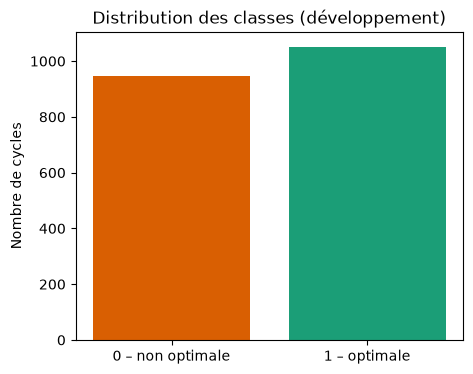

In [11]:
# 1.5 Équilibre des classes (développement)
comptes = y_dev.value_counts().sort_index()
parts = y_dev.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'Effectif': comptes.values, 'Proportion': parts.round(3).values},
                   index=['0 – non optimale', '1 – optimale']))

plt.figure(figsize=(5, 4))
plt.bar(['0 – non optimale', '1 – optimale'], comptes.values, color=['#d95f02', '#1b9e77'])
plt.ylabel('Nombre de cycles')
plt.title('Distribution des classes (développement)')
plt.show()

In [12]:
# 1.5 (suite) Contrôle de représentativité du test final (diagnostic sur profile.txt uniquement)
# Les colonnes Cooler / Pump_leakage / Accumulator servent ici à comparer les jeux, jamais comme variables explicatives.
print(f'Part de valves optimales : développement = {y_dev.mean():.3f} | test final = {y_test.mean():.3f}')
for col in ['Cooler', 'Pump_leakage', 'Accumulator']:
    comp = pd.DataFrame({'Développement': profile_dev[col].value_counts(normalize=True),
                         'Test final': profile_test[col].value_counts(normalize=True)}).fillna(0).round(2)
    print(f'\n{col} :')
    print(comp.sort_index())

Part de valves optimales : développement = 0.526 | test final = 0.356

Cooler :
        Développement  Test final
Cooler                           
3                0.37         0.0
20               0.37         0.0
100              0.27         1.0

Pump_leakage :
              Développement  Test final
Pump_leakage                           
0                      0.56        0.49
1                      0.21        0.31
2                      0.23        0.20

Accumulator :
             Développement  Test final
Accumulator                           
90                    0.33        0.69
100                   0.17        0.31
115                   0.20        0.00
130                   0.30        0.00


#### 1.6. Analyse des corrélations entre les variables. 

In [13]:
# 1.6 Corrélations entre variables et avec la cible
corr = X_dev.corr()
corr_cible = X_dev.apply(lambda col: col.corr(y_dev)).sort_values(key=abs, ascending=False)

print('Les 10 variables les plus corrélées à la cible (valve optimale) :')
print(corr_cible.head(10).round(3))

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
fortes = paires[paires.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'\nPaires de variables fortement corrélées (|r| > 0.95) : {len(fortes)} sur {len(paires)}')
print(fortes.head(10).round(3))

Les 10 variables les plus corrélées à la cible (valve optimale) :
PS2_seg1_mean    0.800
FS1_seg1_mean    0.590
PS2_kurtosis     0.343
PS2_skew        -0.270
FS1_skew        -0.259
PS2_slope       -0.254
FS1_rms          0.239
FS1_mean         0.231
PS2_std         -0.225
FS1_seg5_mean    0.211
dtype: float64

Paires de variables fortement corrélées (|r| > 0.95) : 158 sur 1444
PS2_max        PS2_range        1.000
FS1_max        FS1_range        1.000
FS1_q25        FS1_seg4_mean    1.000
PS2_q75        PS2_seg5_mean    1.000
PS2_mean       PS2_rms          0.999
PS2_seg4_mean  PS2_seg5_mean    0.999
PS2_q75        PS2_seg4_mean    0.999
FS1_seg4_mean  FS1_seg5_mean    0.999
FS1_q25        FS1_seg5_mean    0.999
FS1_mean       FS1_rms          0.998
dtype: float64


#### 1.7. Visualisations (matrice de corrélation, histogrammes, boxplots). 

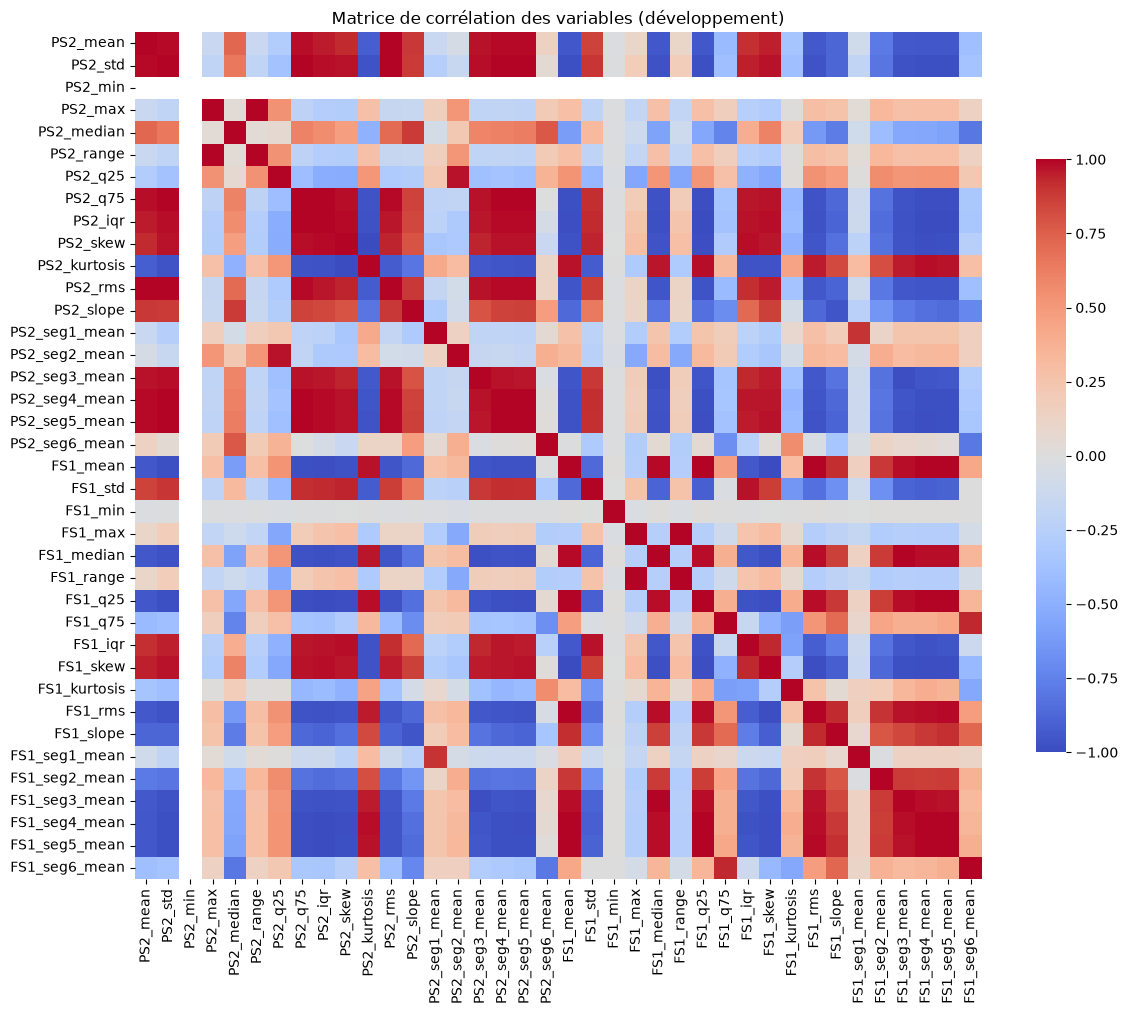

In [14]:
# 1.7 Visualisations : matrice de corrélation
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Matrice de corrélation des variables (développement)')
plt.show()

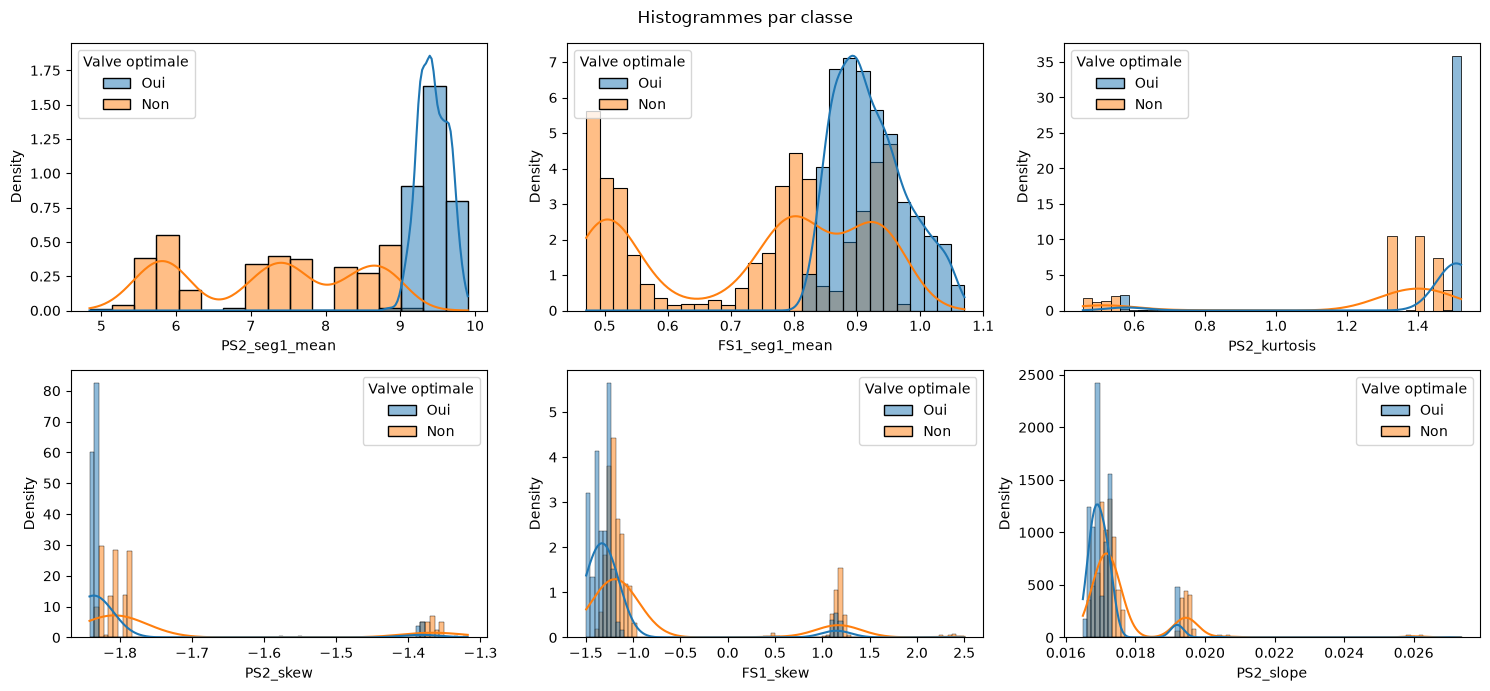

In [15]:
# 1.7 (suite) Histogrammes des 6 variables les plus corrélées à la cible
top6 = corr_cible.index[:6].tolist()
donnees = X_dev[top6].copy()
donnees['Valve optimale'] = y_dev.map({0: 'Non', 1: 'Oui'})

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.histplot(data=donnees, x=col, hue='Valve optimale', kde=True, stat='density', common_norm=False, ax=ax)
fig.suptitle('Histogrammes par classe')
plt.tight_layout()
plt.show()

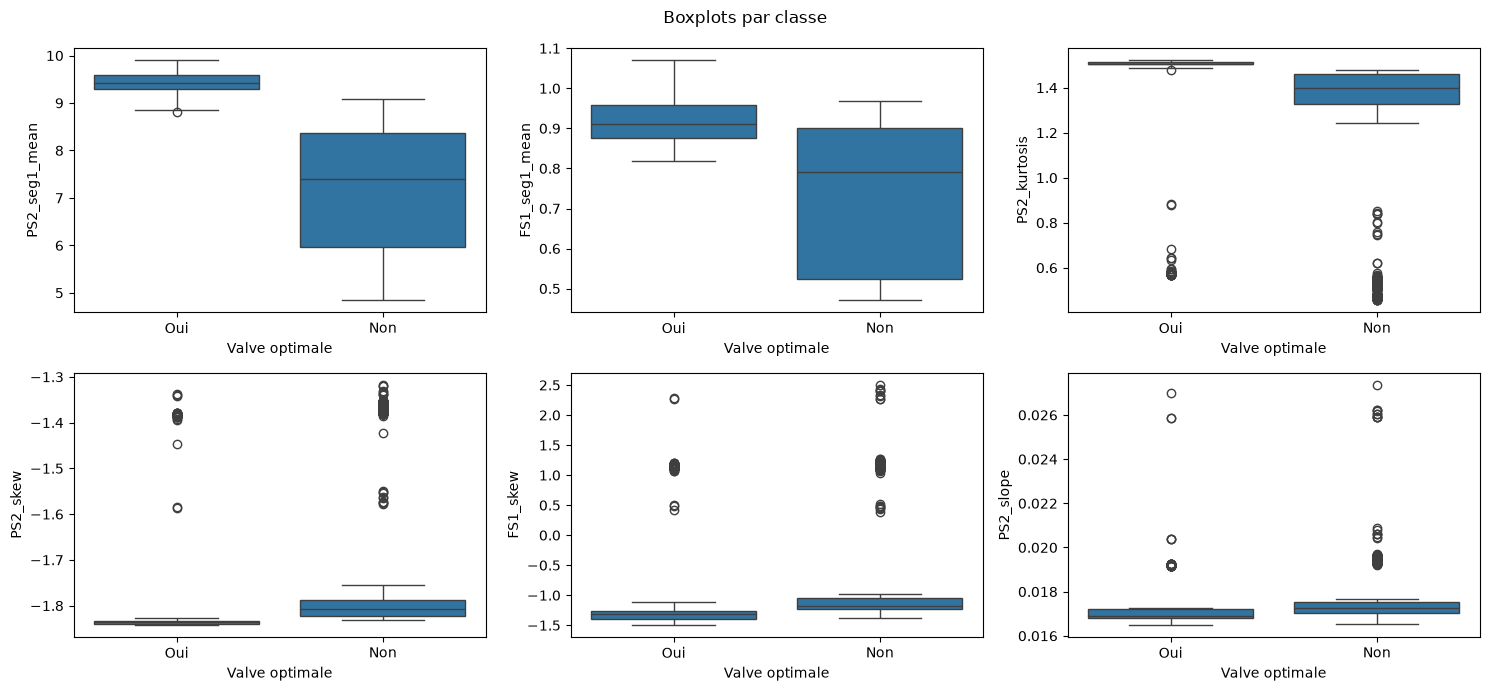

In [16]:
# 1.7 (suite) Boxplots des 6 variables les plus corrélées à la cible
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.boxplot(data=donnees, x='Valve optimale', y=col, ax=ax)
fig.suptitle('Boxplots par classe')
plt.tight_layout()
plt.show()

#### 1.8. Utilisation de méthodes de sélection de variables (Features selection). 

In [17]:
# 1.8 Sélection de variables : filtre de colinéarité et scores de pertinence
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

SEUIL_CORR = 0.95
K_FEATURES = 15

# a) Variables constantes + filtre de colinéarité (priorité aux plus corrélées à la cible)
constantes = X_dev.columns[X_dev.nunique() <= 1].tolist()
gardees = []
for feat in corr_cible.index:
    if feat in constantes:
        continue
    if all(abs(corr.loc[feat, g]) <= SEUIL_CORR for g in gardees):
        gardees.append(feat)
print(f'Variables de départ : {X_dev.shape[1]} | constantes : {len(constantes)} | après filtre de colinéarité : {len(gardees)}')

# b) Trois critères de pertinence
Xs = X_dev[gardees]
f_scores, _ = f_classif(Xs, y_dev)
mi_scores = mutual_info_classif(Xs, y_dev, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                            random_state=RANDOM_STATE, n_jobs=-1).fit(Xs, y_dev)

scores = pd.DataFrame({'ANOVA_F': f_scores, 'Info_mutuelle': mi_scores,
                       'RF_importance': rf.feature_importances_}, index=gardees)

# c) Agrégation par rang moyen (rang 1 = meilleure variable)
scores['Rang_moyen'] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values('Rang_moyen')
print(scores.round(4).head(K_FEATURES + 5))

Variables de départ : 38 | constantes : 1 | après filtre de colinéarité : 16
                 ANOVA_F  Info_mutuelle  RF_importance  Rang_moyen
PS2_seg1_mean  3557.6588         0.6724         0.3721      1.3333
PS2_kurtosis    266.3891         0.6786         0.3165      2.0000
FS1_seg1_mean  1064.9580         0.3671         0.1000      2.6667
PS2_slope       137.2580         0.3169         0.0375      4.6667
FS1_q75          71.3112         0.2337         0.0494      5.0000
FS1_seg6_mean    59.4378         0.2231         0.0379      6.6667
FS1_seg2_mean    58.8154         0.2892         0.0275      7.0000
FS1_std          70.6805         0.1802         0.0272      8.6667
PS2_seg3_mean    59.2863         0.2317         0.0038      9.3333
PS2_q25          26.5242         0.2052         0.0062     10.3333
PS2_seg6_mean     0.4062         0.2129         0.0051     12.0000
FS1_kurtosis      1.2227         0.0877         0.0072     12.0000
PS2_median       14.5911         0.1856         0.00

15 variables retenues :
['PS2_seg1_mean', 'PS2_kurtosis', 'FS1_seg1_mean', 'PS2_slope', 'FS1_q75', 'FS1_seg6_mean', 'FS1_seg2_mean', 'FS1_std', 'PS2_seg3_mean', 'PS2_q25', 'PS2_seg6_mean', 'FS1_kurtosis', 'PS2_median', 'FS1_max', 'PS2_range']


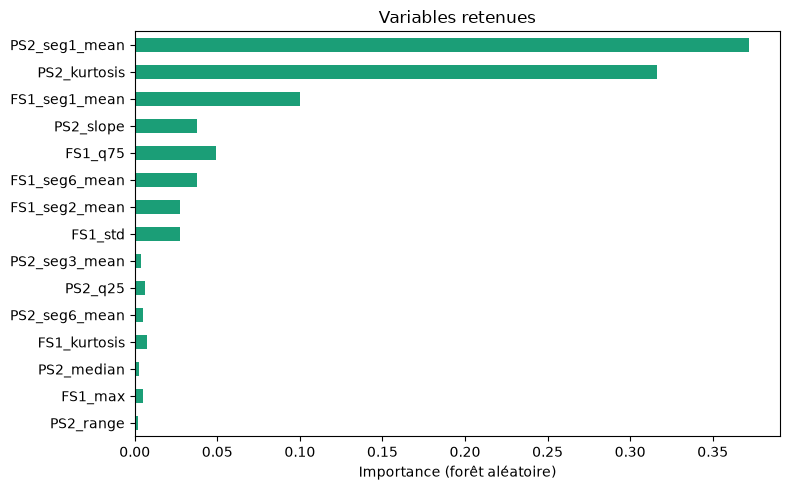

X_dev_sel : (2000, 15) | X_test_sel : (205, 15)


In [18]:
# 1.8 (suite) Variables retenues et jeux de données prêts pour l'étape 2
selected_features = scores.index[:K_FEATURES].tolist()
print(f'{len(selected_features)} variables retenues :')
print(selected_features)

plt.figure(figsize=(8, 5))
scores.loc[selected_features, 'RF_importance'][::-1].plot.barh(color='#1b9e77')
plt.xlabel('Importance (forêt aléatoire)')
plt.title('Variables retenues')
plt.tight_layout()
plt.show()

# Mêmes colonnes pour le test final (aucune statistique du test n'est utilisée)
X_dev_sel, X_test_sel = X_dev[selected_features], X_test[selected_features]
print('X_dev_sel :', X_dev_sel.shape, '| X_test_sel :', X_test_sel.shape)

## 2. Modélisation et évaluation  